<a href="https://colab.research.google.com/github/snigdhareddy-20/-DEEP_LEARNING/blob/main/DL_S1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices('GPU'))

!pip install -q tensorflow-datasets



TensorFlow version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!pip install -q importlib_resources


In [ ]:
import tensorflow_datasets as tfds
import tensorflow as tf

(train_raw, validation_raw), info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True
)

print("Dataset downloaded successfully!")
print("Classes:", info.features["label"].names)
print("Total images:", info.splits["train"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.IC734N_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Dataset downloaded successfully!
Classes: ['cat', 'dog']
Total images: 23262


In [ ]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

AUTOTUNE = tf.data.AUTOTUNE

train_data = (
    train_raw
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

validation_data = (
    validation_raw
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Image preparation completed!")

Image preparation completed!


In [ ]:
model = keras.Sequential([

    layers.Input(shape=(128, 128, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=10
)

Epoch 1/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 58s 80ms/step - accuracy: 0.6044 - loss: 0.6510 - val_accuracy: 0.7259 - val_loss: 0.5535
Epoch 2/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 29s 48ms/step - accuracy: 0.7478 - loss: 0.5195 - val_accuracy: 0.7805 - val_loss: 0.4778
Epoch 3/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.7973 - loss: 0.4353 - val_accuracy: 0.8020 - val_loss: 0.4231
Epoch 4/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 42s 48ms/step - accuracy: 0.8303 - loss: 0.3773 - val_accuracy: 0.8246 - val_loss: 0.4107
Epoch 5/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.8625 - loss: 0.3166 - val_accuracy: 0.8351 - val_loss: 0.4020
Epoch 6/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 29s 48ms/step - accuracy: 0.8875 - loss: 0.2696 - val_accuracy: 0.8392 - val_loss: 0.3920
Epoch 7/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 32s 52ms/step - accuracy: 0.9100 - loss: 0.2198 - val_accuracy: 0.8347 - val_loss: 0.4396
Epoch 8/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 29s 48ms/step - accuracy: 0.9329 - loss: 0.1735 - 

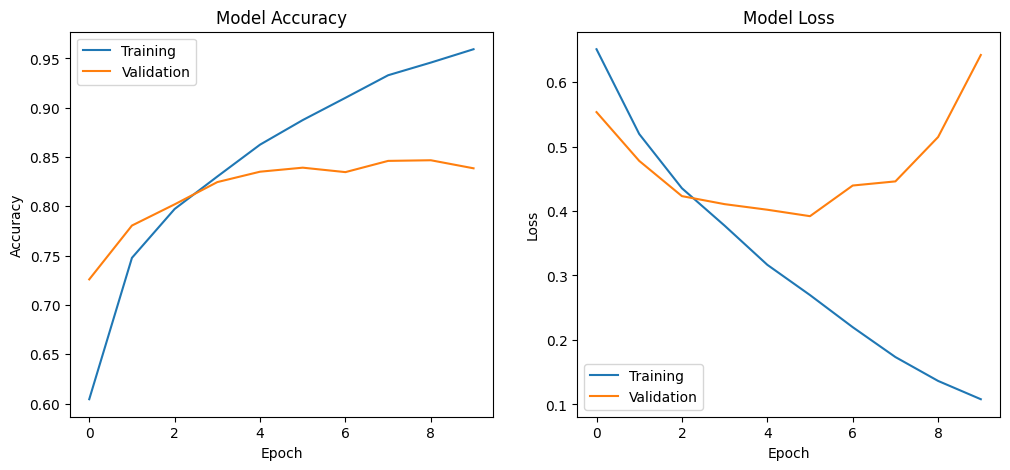

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

Saving Cat_November_2010-1a.jpg.webp to Cat_November_2010-1a.jpg.webp


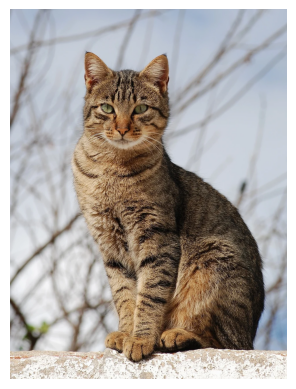

CAT: 100.0 %
DOG: 0.0 %
RESULT: This is a CAT 🐱


In [ ]:
from google.colab import files
from PIL import Image

# Upload an image
uploaded = files.upload()

for filename in uploaded.keys():

    # Open image
    img = Image.open(filename).convert("RGB")

    # Resize image
    img = img.resize((128, 128))

    # Convert into array
    img_array = np.array(img)

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    prediction = model.predict(img_array, verbose=0)[0][0]

    # Calculate probabilities
    cat_probability = (1 - prediction) * 100
    dog_probability = prediction * 100

    # Display image
    plt.imshow(Image.open(filename))
    plt.axis("off")
    plt.show()

    # Display results
    print("CAT:", round(cat_probability, 2), "%")
    print("DOG:", round(dog_probability, 2), "%")

    if prediction < 0.5:
        print("RESULT: This is a CAT 🐱")
    else:
        print("RESULT: This is a DOG 🐶")

In [ ]:
model.save("cat_dog_model.keras")

print("Model saved successfully!")

Model saved successfully!
